# Análise Exploratória de Dados — Olist
## Projeto Aplicado I — *Olist: o Peso da Espera*

**Aluno:** Felipe Passador Leite — RA 10401969
**Organização:** Olist (marketplace brasileiro de e-commerce)
**Problema de pesquisa:** atrasos e tempo de entrega dos pedidos impactam a satisfação do cliente?

Este notebook segue a estrutura de Análise Exploratória de Dados (AED) apresentada na Aula 2
da disciplina: dimensões do dataset, tipos de dados, perfil estatístico de cada coluna,
tratamento inicial, valores ausentes, medidas de posição e dispersão, distribuição e
frequência, outliers e correlações.

**Histórico de versões**
- *Etapa 2 (out/2026):* primeira versão da AED, focada nas variáveis do problema de pesquisa.
- *Etapa 3 (nov/2026):* correção do caminho dos dados, perfil estatístico de **todas as colunas**
  de todas as tabelas, novos gráficos de distribuição, comparação entre pedidos no prazo e
  atrasados e análise por estado — achados que alimentam o esboço do data storytelling.

**Como executar:** abra este notebook a partir da pasta `notebooks/` do repositório e execute
todas as células em ordem (*Kernel → Restart & Run All*). Os CSVs são lidos de `../dados/`.

## 1. Importação das bibliotecas

Bibliotecas de análise de dados (pandas, numpy) e de visualização (matplotlib, seaborn).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual padrão dos gráficos deste notebook.
# Seguindo a orientação da Aula 3 (Storytelling), usamos uma paleta sóbria em tons de cinza,
# com uma única cor de destaque (vermelho) reservada para o que é "problema" (atraso).
COR_PRINCIPAL = "#4d4d4d"   # cinza escuro
COR_SECUNDARIA = "#a6a6a6"  # cinza claro
COR_DESTAQUE = "#b22222"    # vermelho — usado só para destacar atraso

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 2. Carregamento dos dados

Carregamos as 9 tabelas do dataset "Brazilian E-Commerce Public Dataset by Olist",
armazenadas na pasta `dados/` do repositório do projeto.

In [2]:
# O notebook fica em notebooks/, e os dados em dados/ (uma pasta acima).
caminho = "../dados/"

customers = pd.read_csv(caminho + "olist_customers_dataset.csv")
geolocation = pd.read_csv(caminho + "olist_geolocation_dataset.csv")
order_items = pd.read_csv(caminho + "olist_order_items_dataset.csv")
order_payments = pd.read_csv(caminho + "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(caminho + "olist_order_reviews_dataset.csv")
orders = pd.read_csv(caminho + "olist_orders_dataset.csv")
products = pd.read_csv(caminho + "olist_products_dataset.csv")
sellers = pd.read_csv(caminho + "olist_sellers_dataset.csv")
category_translation = pd.read_csv(caminho + "product_category_name_translation.csv")

tabelas = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "order_payments": order_payments,
    "order_reviews": order_reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation,
}
print("Tabelas carregadas:", list(tabelas.keys()))


Tabelas carregadas: ['customers', 'geolocation', 'order_items', 'order_payments', 'order_reviews', 'orders', 'products', 'sellers', 'category_translation']


## 3. Dimensões e tipos de dados

Para cada tabela, verificamos o número de linhas (exemplares), número de colunas (dimensões)
e o tipo de dado de cada coluna — primeira pergunta de qualquer Análise Exploratória de Dados.

In [3]:
for nome, df in tabelas.items():
    print(f"--- {nome} ---")
    print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
    print(df.dtypes.to_string())
    print()


--- customers ---
Linhas: 99,441 | Colunas: 5
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str

--- geolocation ---
Linhas: 1,000,163 | Colunas: 5
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str

--- order_items ---
Linhas: 112,650 | Colunas: 7
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64

--- order_payments ---
Linhas: 103,886 | Colunas: 5
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64

--- order_reviews ---
Linhas: 99,224 | Colunas: 7
review

## 4. Perfil estatístico de cada coluna

Para atender à descrição completa das variáveis, montamos uma função que gera, para **cada
coluna** de uma tabela, um resumo com:

- tipo de dado, quantidade de exemplares (valores preenchidos), quantidade e percentual de
  valores ausentes (NAs) e quantidade de valores distintos;
- para colunas **numéricas**: mínimo, máximo, média, mediana, variância, desvio padrão,
  assimetria (indica para que lado a distribuição "se estica") e quantidade de outliers pelo
  método do intervalo interquartil (IQR);
- para colunas **de data** (depois de convertidas, na seção 5): a data mínima e a máxima;
- para colunas **de texto/categóricas**: o valor mais frequente e quantas vezes ele aparece.

**Atenção:** algumas colunas são numéricas no arquivo, mas na verdade são *códigos* (por
exemplo, o prefixo do CEP). Calcular média de CEP não faz sentido, então essas colunas são
tratadas como categóricas na função (parâmetro `colunas_codigo`).

In [4]:
def contar_outliers_iqr(serie):
    """Conta quantos valores estão fora do intervalo [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]."""
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


def perfil_colunas(df, colunas_codigo=()):
    """Retorna um DataFrame com uma linha de resumo estatístico para cada coluna de df."""
    linhas = []
    for col in df.columns:
        s = df[col]
        info = {
            "coluna": col,
            "tipo": str(s.dtype),
            "n_preenchidos": int(s.notna().sum()),
            "n_ausentes": int(s.isna().sum()),
            "pct_ausentes": round(s.isna().mean() * 100, 2),
            "n_distintos": int(s.nunique()),
        }
        eh_numerica = pd.api.types.is_numeric_dtype(s) and col not in colunas_codigo
        if pd.api.types.is_datetime64_any_dtype(s):
            # Para datas, o mínimo e o máximo mostram o período coberto pelos dados
            info.update({"minimo": s.min(), "maximo": s.max()})
        elif eh_numerica:
            info.update({
                "minimo": s.min(),
                "maximo": s.max(),
                "media": round(s.mean(), 2),
                "mediana": s.median(),
                "variancia": round(s.var(), 2),
                "desvio_padrao": round(s.std(), 2),
                "assimetria": round(s.skew(), 2),
                "n_outliers_iqr": contar_outliers_iqr(s),
            })
        else:
            moda = s.mode()
            if not moda.empty:
                info["valor_mais_frequente"] = str(moda.iloc[0])[:30]
                info["freq_valor_mais_frequente"] = int((s == moda.iloc[0]).sum())
        linhas.append(info)
    return pd.DataFrame(linhas).set_index("coluna")


# Colunas numéricas que, na verdade, são códigos (não faz sentido calcular média etc.)
codigos = {"customer_zip_code_prefix", "geolocation_zip_code_prefix", "seller_zip_code_prefix",
           "order_item_id", "payment_sequential"}

perfis = {}
for nome, df in tabelas.items():
    perfis[nome] = perfil_colunas(df, colunas_codigo=codigos)
    print(f"\n================ {nome} ({len(df):,} linhas) ================")
    print(perfis[nome].to_string())


================ customers (99,441 linhas) ================
                           tipo  n_preenchidos  n_ausentes  pct_ausentes  n_distintos            valor_mais_frequente  freq_valor_mais_frequente
coluna                                                                                                                                          
customer_id                 str          99441           0           0.0        99441  00012a2ce6f8dcda20d059ce984917                          1
customer_unique_id          str          99441           0           0.0        96096  8d50f5eadf50201ccdcedfb9e2ac84                         17
customer_zip_code_prefix  int64          99441           0           0.0        14994                           22790                        142
customer_city               str          99441           0           0.0         4119                       sao paulo                      15540
customer_state              str          99441           0           


================ geolocation (1,000,163 linhas) ================
                                tipo  n_preenchidos  n_ausentes  pct_ausentes  n_distintos valor_mais_frequente  freq_valor_mais_frequente      minimo      maximo  media    mediana  variancia  desvio_padrao  assimetria  n_outliers_iqr
coluna                                                                                                                                                                                                                                    
geolocation_zip_code_prefix    int64        1000163           0           0.0        19015                24220                     1146.0         NaN         NaN    NaN        NaN        NaN            NaN         NaN             NaN
geolocation_lat              float64        1000163           0           0.0       717360                  NaN                        NaN  -36.605374   45.065933 -21.18 -22.919377      32.67           5.72        1.57        168


================ order_payments (103,886 linhas) ================
                         tipo  n_preenchidos  n_ausentes  pct_ausentes  n_distintos            valor_mais_frequente  freq_valor_mais_frequente  minimo    maximo   media  mediana  variancia  desvio_padrao  assimetria  n_outliers_iqr
coluna                                                                                                                                                                                                                                 
order_id                  str         103886           0           0.0        99440  fa65dad1b0e818e3ccc5cb0e392313                       29.0     NaN       NaN     NaN      NaN        NaN            NaN         NaN             NaN
payment_sequential      int64         103886           0           0.0           29                               1                    99360.0     NaN       NaN     NaN      NaN        NaN            NaN         NaN             NaN
payme


================ order_reviews (99,224 linhas) ================
                          tipo  n_preenchidos  n_ausentes  pct_ausentes  n_distintos            valor_mais_frequente  freq_valor_mais_frequente  minimo  maximo  media  mediana  variancia  desvio_padrao  assimetria  n_outliers_iqr
coluna                                                                                                                                                                                                                               
review_id                  str          99224           0          0.00        98410  08528f70f579f0c830189efc523d21                        3.0     NaN     NaN    NaN      NaN        NaN            NaN         NaN             NaN
order_id                   str          99224           0          0.00        98673  03c939fd7fd3b38f8485a0f95798f1                        3.0     NaN     NaN    NaN      NaN        NaN            NaN         NaN             NaN
review_score   


================ orders (99,441 linhas) ================
                              tipo  n_preenchidos  n_ausentes  pct_ausentes  n_distintos            valor_mais_frequente  freq_valor_mais_frequente
coluna                                                                                                                                             
order_id                       str          99441           0          0.00        99441  00010242fe8c5a6d1ba2dd792cb162                          1
customer_id                    str          99441           0          0.00        99441  00012a2ce6f8dcda20d059ce984917                          1
order_status                   str          99441           0          0.00            8                       delivered                      96478
order_purchase_timestamp       str          99441           0          0.00        98875             2017-11-20 10:59:08                          3
order_approved_at              str          99281     

In [5]:
# Salvamos o perfil de todas as tabelas em um único CSV, que serve de apoio para a
# seção de Análise Exploratória do documento do projeto.
perfil_geral = pd.concat(perfis, names=["tabela", "coluna"])
perfil_geral.to_csv("perfil_colunas.csv")
print("Arquivo perfil_colunas.csv salvo com", len(perfil_geral), "colunas descritas.")

Arquivo perfil_colunas.csv salvo com 52 colunas descritas.


## 5. Tratamento inicial dos dados

As colunas de data na tabela `orders` estão como texto (object); convertemos para o tipo
datetime, o que é necessário antes de calcular prazos de entrega.

Em seguida, criamos duas variáveis novas (feature engineering), centrais para o problema
de pesquisa deste projeto:

- **atraso_entrega_dias**: diferença, em dias, entre a data real de entrega ao cliente e a
  data estimada. Valores positivos indicam atraso; valores negativos indicam entrega
  adiantada.
- **tempo_entrega_dias**: tempo total, em dias, entre a compra e a entrega ao cliente.


In [6]:
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in colunas_data:
    orders[c] = pd.to_datetime(orders[c])

orders["atraso_entrega_dias"] = (
    orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]
).dt.days

orders["tempo_entrega_dias"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.days

orders[["order_id", "order_estimated_delivery_date", "order_delivered_customer_date",
        "atraso_entrega_dias", "tempo_entrega_dias"]].head()


,order_id,order_estimated_delivery_date,order_delivered_customer_date,atraso_entrega_dias,tempo_entrega_dias
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-18,2017-10-10 21:25:13,-8.0,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-13,2018-08-07 15:27:45,-6.0,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-09-04,2018-08-17 18:06:29,-18.0,9.0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-15,2017-12-02 00:28:42,-13.0,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-26,2018-02-16 18:17:02,-10.0,2.0


In [7]:
# Perfil das colunas de data (já convertidas) e das duas variáveis novas
perfil_datas = perfil_colunas(orders[colunas_data + ["atraso_entrega_dias", "tempo_entrega_dias"]])
perfil_datas.to_csv("perfil_datas_orders.csv")
perfil_datas

,tipo,n_preenchidos,n_ausentes,pct_ausentes,n_distintos,minimo,maximo,media,mediana,variancia,desvio_padrao,assimetria,n_outliers_iqr
coluna,,,,,,,,,,,,,
order_purchase_timestamp,datetime64[us],99441,0,0.00,98875,2016-09-04 21:15:19,2018-10-17 17:30:18,NaN,NaN,NaN,NaN,NaN,NaN
order_approved_at,datetime64[us],99281,160,0.16,90733,2016-09-15 12:16:38,2018-09-03 17:40:06,NaN,NaN,NaN,NaN,NaN,NaN
order_delivered_carrier_date,datetime64[us],97658,1783,1.79,81018,2016-10-08 10:34:01,2018-09-11 19:48:28,NaN,NaN,NaN,NaN,NaN,NaN
order_delivered_customer_date,datetime64[us],96476,2965,2.98,95664,2016-10-11 13:46:32,2018-10-17 13:22:46,NaN,NaN,NaN,NaN,NaN,NaN
order_estimated_delivery_date,datetime64[us],99441,0,0.00,459,2016-09-30 00:00:00,2018-11-12 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
atraso_entrega_dias,float64,96476,2965,2.98,198,-147.0,188.0,-11.88,-12.0,103.71,10.18,2.01,4301.0
tempo_entrega_dias,float64,96476,2965,2.98,146,0.0,209.0,12.09,10.0,91.24,9.55,3.83,5025.0


## 6. Valores ausentes (missing values)

Contagem de valores nulos por coluna, nas tabelas mais relevantes para o problema de
pesquisa (`orders` e `order_reviews`).

In [8]:
print("Valores nulos — orders:")
print(orders.isnull().sum()[orders.isnull().sum() > 0])
print()
print("Valores nulos — order_reviews:")
print(order_reviews.isnull().sum()[order_reviews.isnull().sum() > 0])


Valores nulos — orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
atraso_entrega_dias              2965
tempo_entrega_dias               2965
dtype: int64

Valores nulos — order_reviews:


review_comment_title      87656
review_comment_message    58247
dtype: int64


In [9]:
# Quantos pedidos não têm data de entrega registrada (não chegaram ao cliente)?
pedidos_sem_entrega = orders["order_delivered_customer_date"].isnull().sum()
total_pedidos = len(orders)
print(f"Pedidos sem data de entrega registrada: {pedidos_sem_entrega} de {total_pedidos} "
      f"({pedidos_sem_entrega/total_pedidos:.2%})")
print()
print("Distribuição do status desses pedidos sem entrega registrada:")
print(orders.loc[orders["order_delivered_customer_date"].isnull(), "order_status"].value_counts())


Pedidos sem data de entrega registrada: 2965 de 99441 (2.98%)

Distribuição do status desses pedidos sem entrega registrada:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


## 7. Medidas de posição e dispersão

Para as variáveis numéricas centrais do problema de pesquisa (`atraso_entrega_dias`,
`tempo_entrega_dias` e `review_score`), calculamos as medidas de tendência central
(média, mediana, moda), as separatrizes (quartis) e as medidas de dispersão
(variância, desvio padrão e coeficiente de variação).

In [10]:
def resumo_estatistico(serie, nome):
    s = serie.dropna()
    media = s.mean()
    mediana = s.median()
    moda = s.mode().iloc[0] if not s.mode().empty else np.nan
    variancia = s.var()
    desvio = s.std()
    cv = (desvio / media * 100) if media != 0 else np.nan
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    print(f"--- {nome} ---")
    print(f"Contagem (n)        : {s.shape[0]:,}")
    print(f"Média               : {media:.2f}")
    print(f"Mediana             : {mediana:.2f}")
    print(f"Moda                : {moda:.2f}")
    print(f"Mínimo              : {s.min():.2f}")
    print(f"Máximo              : {s.max():.2f}")
    print(f"Q1 (25%)            : {q1:.2f}")
    print(f"Q3 (75%)            : {q3:.2f}")
    print(f"Variância           : {variancia:.2f}")
    print(f"Desvio padrão       : {desvio:.2f}")
    print(f"Coeficiente de var. : {cv:.2f}%")
    print()

resumo_estatistico(orders["atraso_entrega_dias"], "Atraso de entrega (dias)")
resumo_estatistico(orders["tempo_entrega_dias"], "Tempo total de entrega (dias)")
resumo_estatistico(order_reviews["review_score"], "Nota de avaliação (review_score)")


--- Atraso de entrega (dias) ---
Contagem (n)        : 96,476
Média               : -11.88
Mediana             : -12.00
Moda                : -14.00
Mínimo              : -147.00
Máximo              : 188.00
Q1 (25%)            : -17.00
Q3 (75%)            : -7.00
Variância           : 103.71
Desvio padrão       : 10.18
Coeficiente de var. : -85.75%

--- Tempo total de entrega (dias) ---
Contagem (n)        : 96,476
Média               : 12.09
Mediana             : 10.00
Moda                : 7.00
Mínimo              : 0.00
Máximo              : 209.00
Q1 (25%)            : 6.00
Q3 (75%)            : 15.00
Variância           : 91.24
Desvio padrão       : 9.55
Coeficiente de var. : 78.98%

--- Nota de avaliação (review_score) ---
Contagem (n)        : 99,224
Média               : 4.09
Mediana             : 5.00
Moda                : 5.00
Mínimo              : 1.00
Máximo              : 5.00
Q1 (25%)            : 4.00
Q3 (75%)            : 5.00
Variância           : 1.82
Desvio padrão  

## 8. Distribuição e frequência

Visualizamos a distribuição do atraso de entrega e a frequência das notas de avaliação.

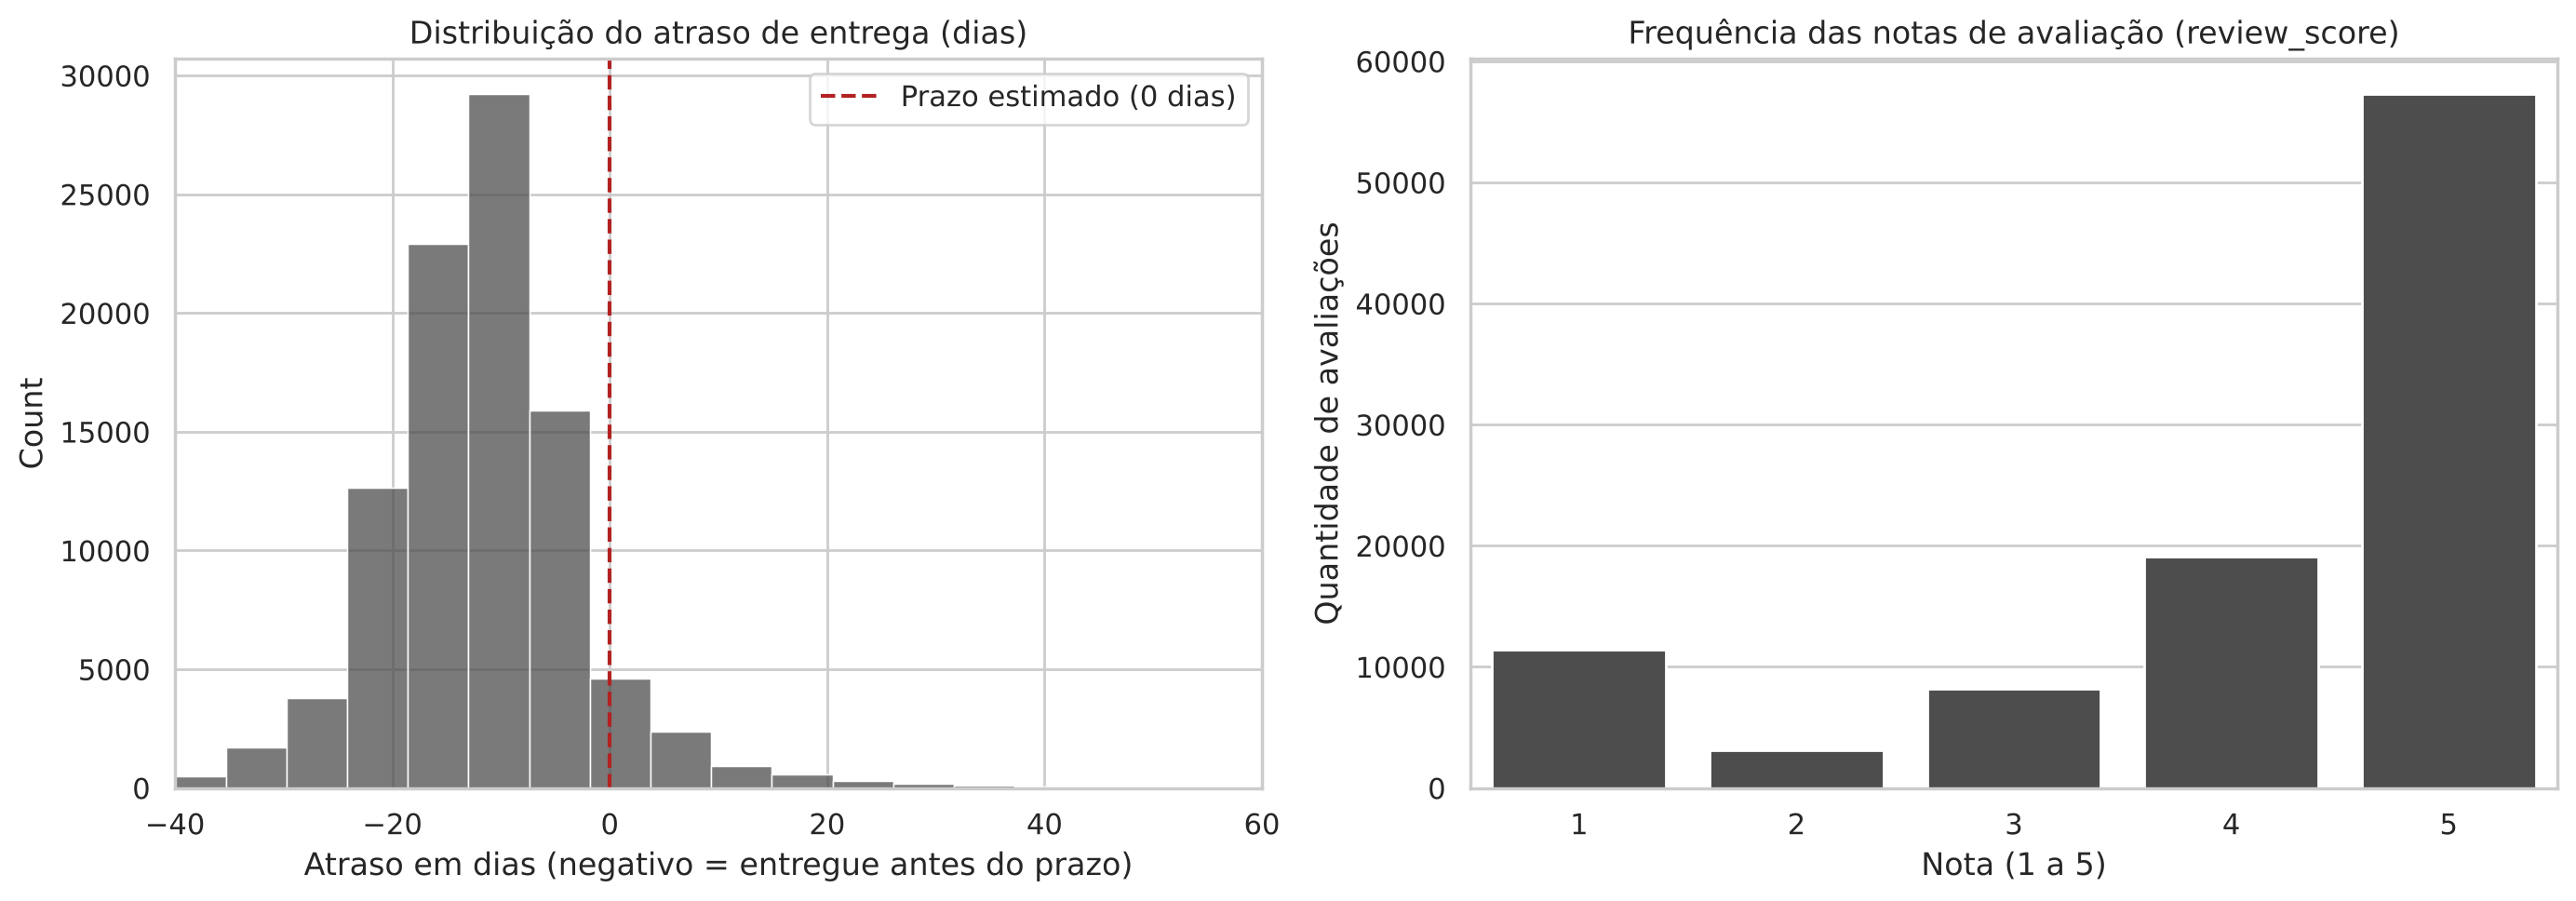

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(orders["atraso_entrega_dias"].dropna(), bins=60, ax=axes[0], color=COR_PRINCIPAL)
axes[0].axvline(0, color=COR_DESTAQUE, linestyle="--", label="Prazo estimado (0 dias)")
axes[0].set_title("Distribuição do atraso de entrega (dias)")
axes[0].set_xlabel("Atraso em dias (negativo = entregue antes do prazo)")
axes[0].set_xlim(-40, 60)
axes[0].legend()

sns.countplot(x="review_score", data=order_reviews, ax=axes[1], color=COR_PRINCIPAL)
axes[1].set_title("Frequência das notas de avaliação (review_score)")
axes[1].set_xlabel("Nota (1 a 5)")
axes[1].set_ylabel("Quantidade de avaliações")

plt.tight_layout()
plt.savefig("distribuicao_atraso_reviews.png", dpi=120)
plt.show()


In [12]:
# Frequência relativa dos status de pedido
print("Frequência dos status de pedido (order_status):")
print(orders["order_status"].value_counts())
print()
print("Frequência relativa (%):")
print((orders["order_status"].value_counts(normalize=True) * 100).round(2))


Frequência dos status de pedido (order_status):
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Frequência relativa (%):
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


### 8.1 Distribuição das demais variáveis numéricas

Além das variáveis centrais do problema, olhamos a distribuição de outras variáveis numéricas
do dataset (preço, frete, valor pago, parcelas, peso e quantidade de fotos do produto).
Como várias delas têm cauda longa à direita (poucos valores muito altos), cortamos o eixo X
no percentil 99 para que o "miolo" da distribuição fique visível — os valores extremos
continuam contabilizados no perfil estatístico da seção 4.

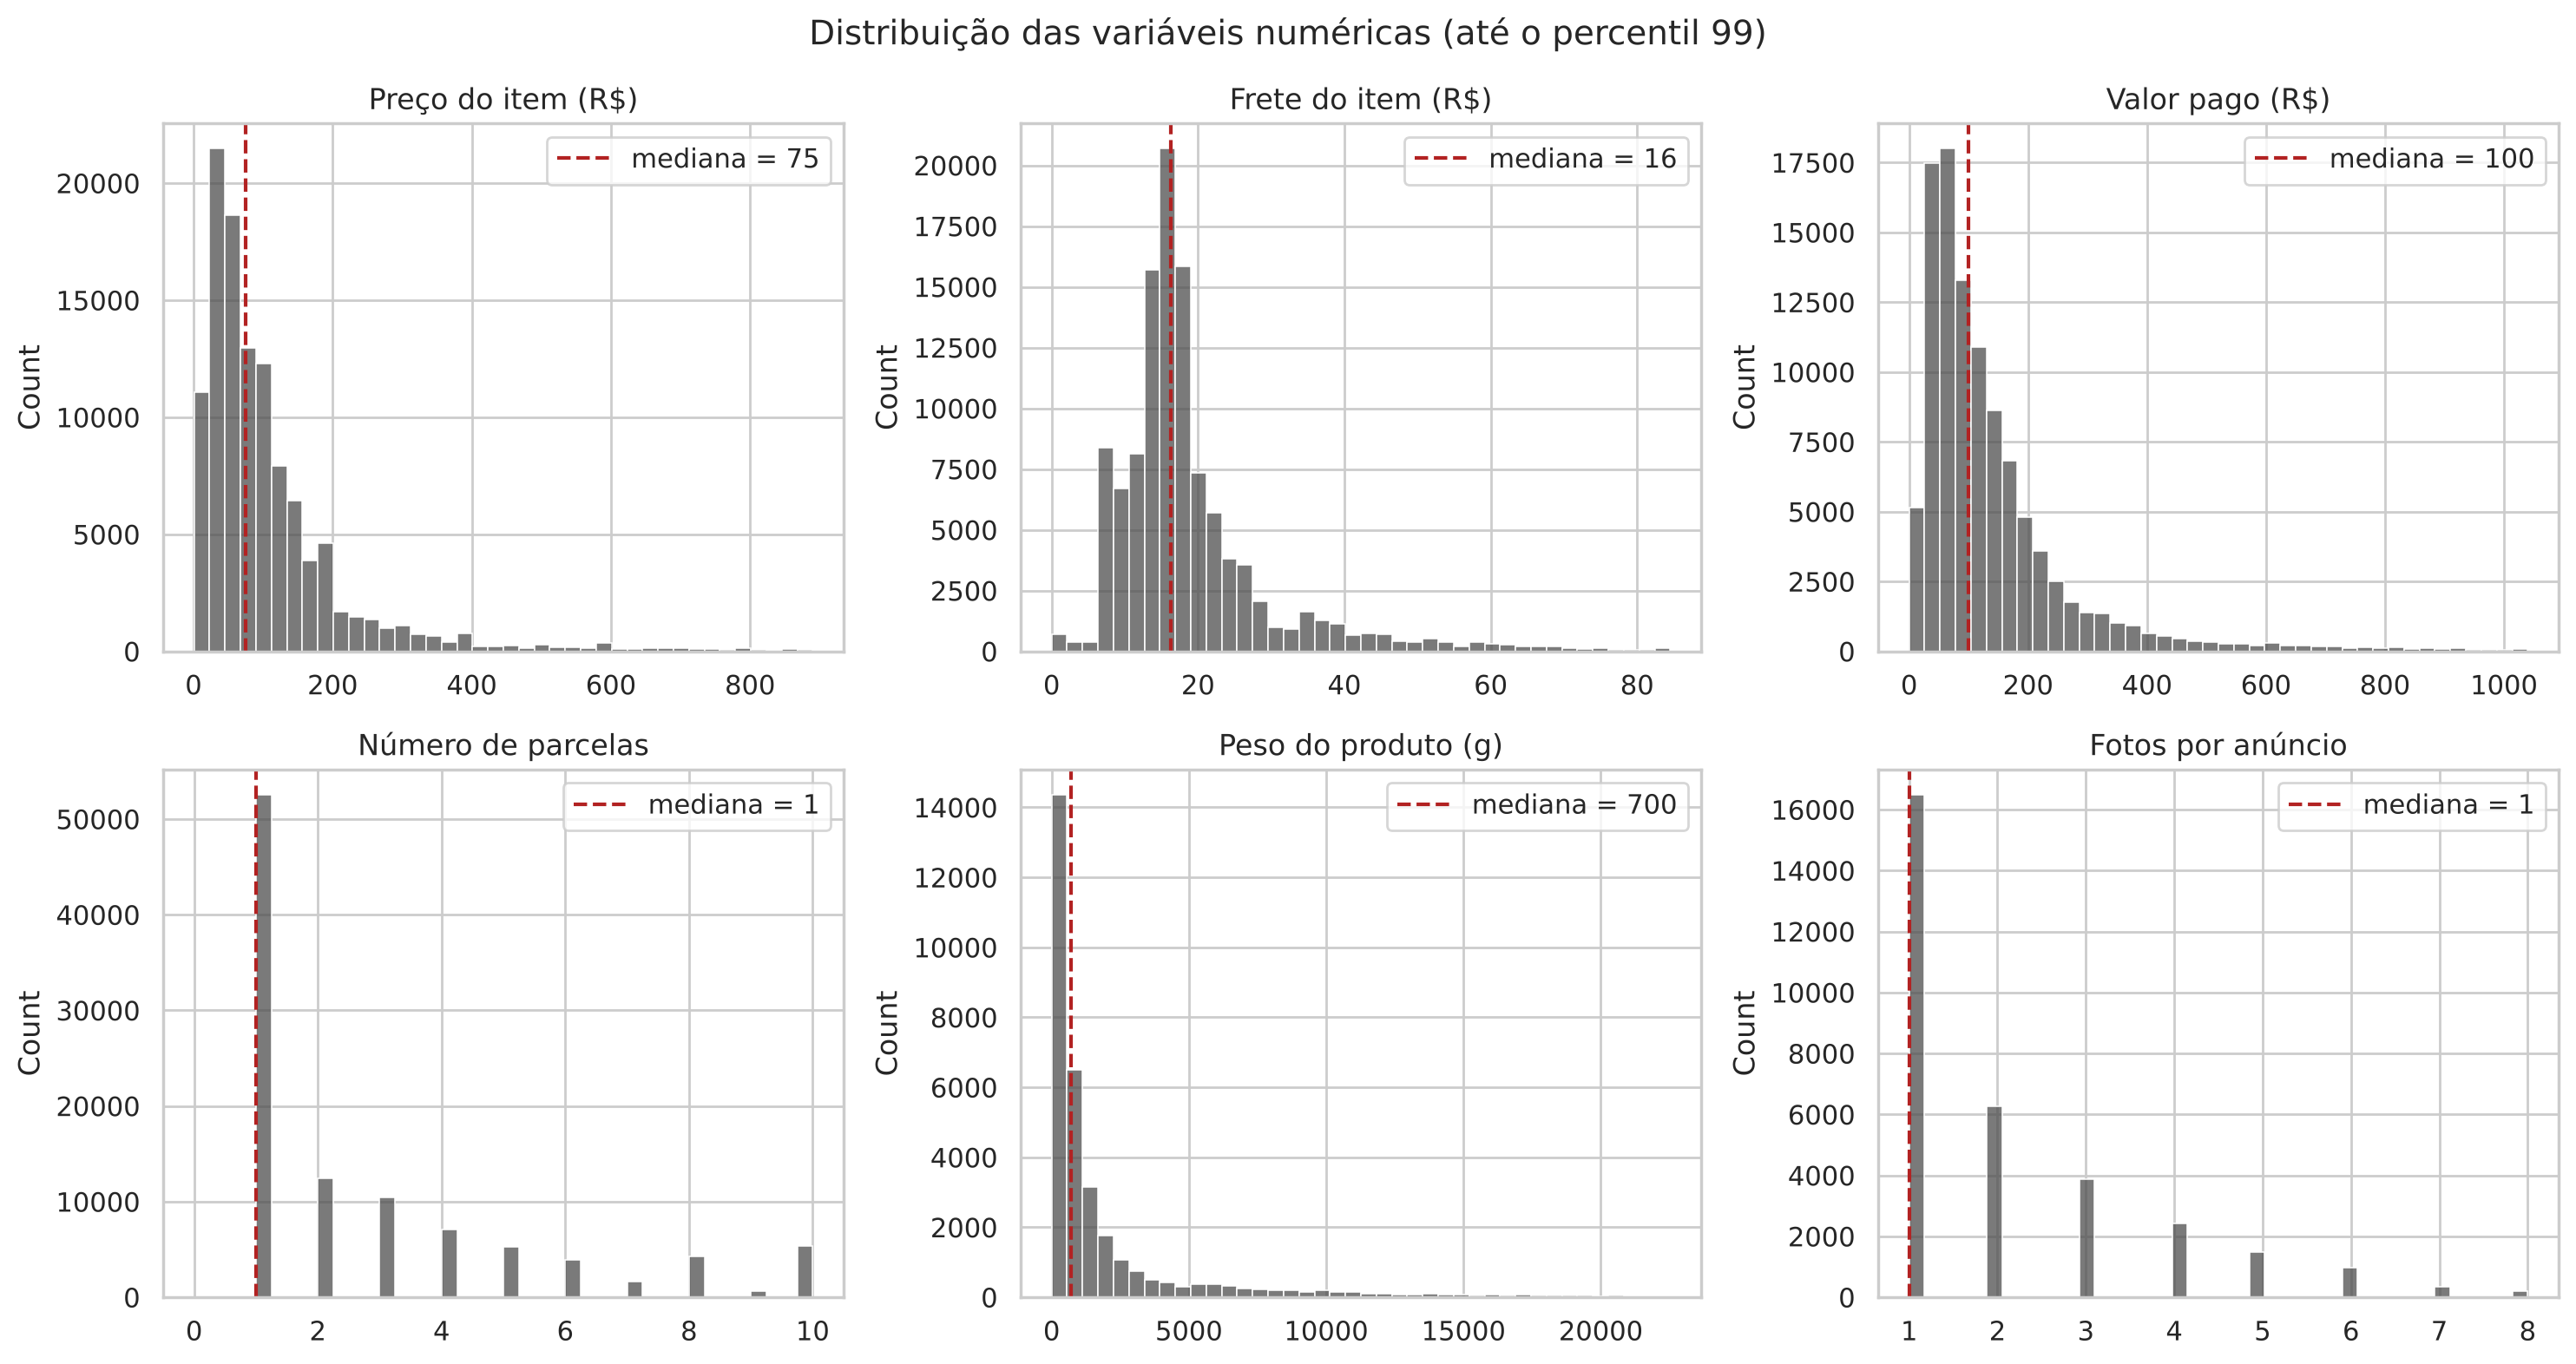

In [13]:
variaveis = [
    (order_items, "price", "Preço do item (R$)"),
    (order_items, "freight_value", "Frete do item (R$)"),
    (order_payments, "payment_value", "Valor pago (R$)"),
    (order_payments, "payment_installments", "Número de parcelas"),
    (products, "product_weight_g", "Peso do produto (g)"),
    (products, "product_photos_qty", "Fotos por anúncio"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (df, col, titulo) in zip(axes.flat, variaveis):
    s = df[col].dropna()
    limite = s.quantile(0.99)
    sns.histplot(s[s <= limite], bins=40, ax=ax, color=COR_PRINCIPAL)
    ax.axvline(s.median(), color=COR_DESTAQUE, linestyle="--", label=f"mediana = {s.median():.0f}")
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.legend()

plt.suptitle("Distribuição das variáveis numéricas (até o percentil 99)", fontsize=14)
plt.tight_layout()
plt.savefig("distribuicao_variaveis_numericas.png", dpi=120)
plt.show()

In [14]:
# Frequência das principais variáveis categóricas
print("Tipo de pagamento (payment_type):")
print((order_payments["payment_type"].value_counts(normalize=True) * 100).round(2))
print()
print("Estados com mais clientes (customer_state) — top 5:")
print((customers["customer_state"].value_counts(normalize=True) * 100).round(2).head(5))
print()
print("Categorias de produto mais frequentes nos itens vendidos — top 5:")
itens_cat = order_items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
print(itens_cat["product_category_name"].value_counts().head(5))

Tipo de pagamento (payment_type):
payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

Estados com mais clientes (customer_state) — top 5:
customer_state
SP    41.98
RJ    12.92
MG    11.70
RS     5.50
PR     5.07
Name: proportion, dtype: float64

Categorias de produto mais frequentes nos itens vendidos — top 5:
product_category_name
cama_mesa_banho           11115
beleza_saude               9670
esporte_lazer              8641
moveis_decoracao           8334
informatica_acessorios     7827
Name: count, dtype: int64


## 9. Outliers (valores anômalos)

Usamos o método do intervalo interquartil (IQR) para identificar outliers na variável de
atraso de entrega, e um boxplot para visualizá-los.

In [15]:
serie = orders["atraso_entrega_dias"].dropna()
q1, q3 = serie.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = serie[(serie < limite_inferior) | (serie > limite_superior)]
print(f"Limite inferior (IQR): {limite_inferior:.1f} dias")
print(f"Limite superior (IQR): {limite_superior:.1f} dias")
print(f"Quantidade de outliers: {len(outliers):,} ({len(outliers)/len(serie):.2%} dos pedidos com data de entrega)")
print(f"Maior atraso observado: {serie.max():.0f} dias")


Limite inferior (IQR): -32.0 dias
Limite superior (IQR): 8.0 dias
Quantidade de outliers: 4,301 (4.46% dos pedidos com data de entrega)
Maior atraso observado: 188 dias


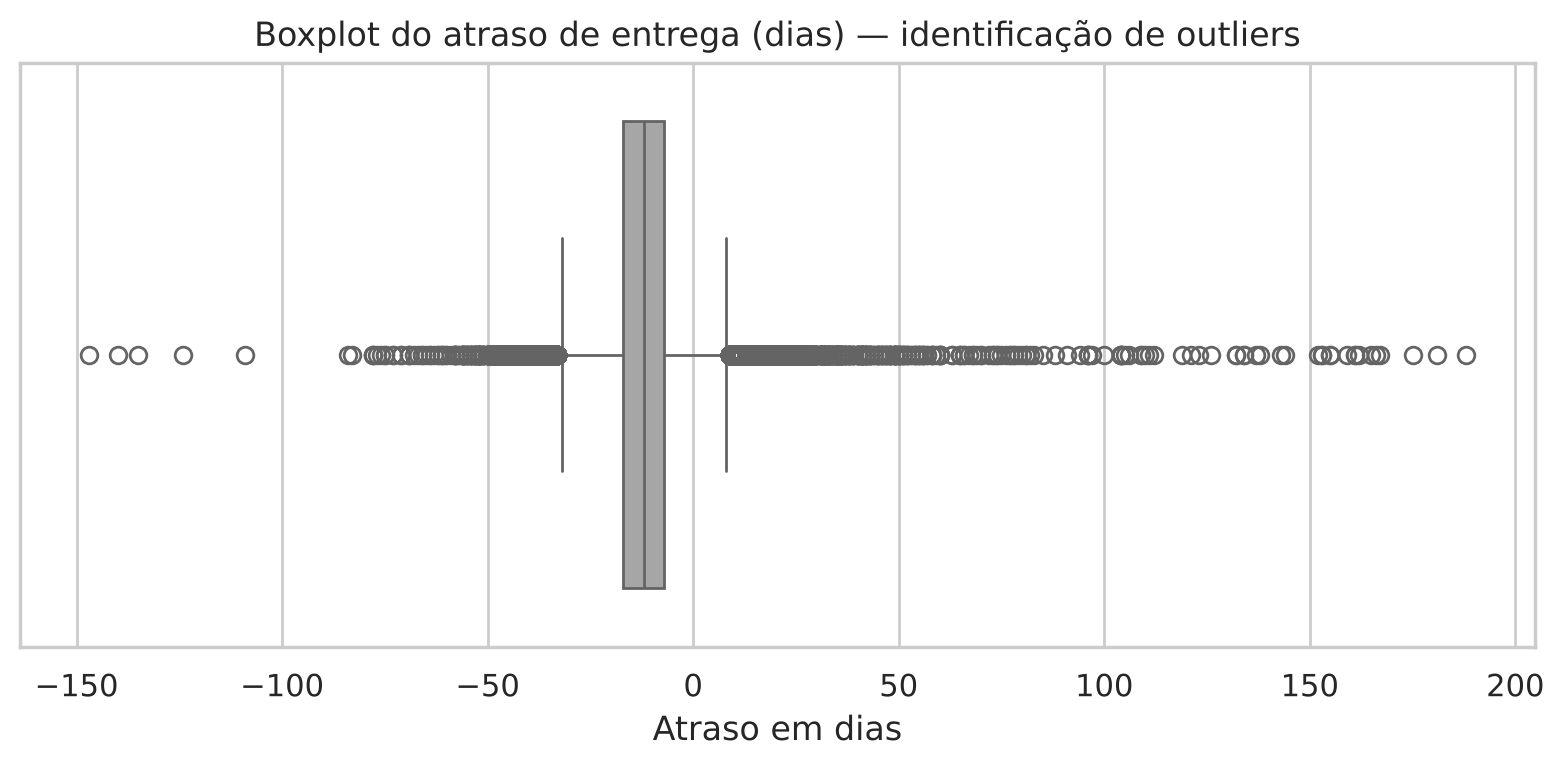

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=orders["atraso_entrega_dias"].dropna(), ax=ax, color=COR_SECUNDARIA)
ax.set_title("Boxplot do atraso de entrega (dias) — identificação de outliers")
ax.set_xlabel("Atraso em dias")
plt.tight_layout()
plt.savefig("boxplot_atraso.png", dpi=120)
plt.show()


**Observação sobre `review_score`:** como a nota é uma escala discreta de 1 a 5 e a maioria
das notas é 4 ou 5 (Q1 = 4), o método IQR classifica todas as notas 1 e 2 como "outliers".
Elas não são erros: são justamente os clientes insatisfeitos que interessam ao estudo. Por isso,
o IQR é usado aqui apenas como referência, e não como critério para remover dados.

**Observação sobre a geolocalização:** a tabela `geolocation` tem latitudes e longitudes
máximas fora do território brasileiro, o que indica erro de cadastro em parte das coordenadas.
A célula abaixo conta esses casos usando um retângulo aproximado em volta do Brasil.

In [17]:
# Retângulo aproximado do território brasileiro (latitude e longitude)
fora_brasil = geolocation[
    (geolocation["geolocation_lat"] > 5.3) | (geolocation["geolocation_lat"] < -33.8) |
    (geolocation["geolocation_lng"] > -34.7) | (geolocation["geolocation_lng"] < -73.99)
]
print(f"Coordenadas fora do Brasil: {len(fora_brasil):,} de {len(geolocation):,} "
      f"({len(fora_brasil)/len(geolocation):.3%})")

Coordenadas fora do Brasil: 42 de 1,000,163 (0.004%)


In [18]:
# Resumo de outliers (método IQR) para todas as colunas numéricas do dataset
resumo_outliers = (
    perfil_geral.dropna(subset=["n_outliers_iqr"])
    [["n_preenchidos", "n_outliers_iqr"]]
    .assign(pct_outliers=lambda d: (d["n_outliers_iqr"] / d["n_preenchidos"] * 100).round(2))
    .sort_values("pct_outliers", ascending=False)
)
resumo_outliers

,,n_preenchidos,n_outliers_iqr,pct_outliers
tabela,coluna,,,
geolocation,geolocation_lat,1000163,168240.0,16.82
order_reviews,review_score,99224,14575.0,14.69
products,product_weight_g,32949,4551.0,13.81
order_items,freight_value,112650,12134.0,10.77
order_payments,payment_value,103886,7981.0,7.68
order_items,price,112650,8427.0,7.48
products,product_description_lenght,32341,2078.0,6.43
order_payments,payment_installments,103886,6313.0,6.08
products,product_height_cm,32949,1892.0,5.74


## 10. Correlação entre atraso de entrega e satisfação do cliente

Esta seção aborda diretamente o problema de pesquisa do projeto: existe relação entre
atraso na entrega e a nota de avaliação dada pelo cliente?

Para isso, juntamos (merge) a tabela `orders` (que contém o atraso calculado) com a tabela
`order_reviews` (que contém a nota), por meio da chave `order_id`.

In [19]:
orders_reviews = orders.merge(order_reviews[["order_id", "review_score"]], on="order_id", how="inner")

correlacao = orders_reviews[["atraso_entrega_dias", "review_score"]].corr().iloc[0, 1]
print(f"Correlação entre atraso de entrega e nota de avaliação: {correlacao:.3f}")
print("(valores negativos indicam que, quanto maior o atraso, menor tende a ser a nota)")


Correlação entre atraso de entrega e nota de avaliação: -0.267
(valores negativos indicam que, quanto maior o atraso, menor tende a ser a nota)


Atraso médio de entrega (dias), por nota de avaliação:
review_score
1    -4.06
2    -8.63
3   -10.77
4   -12.38
5   -13.39
Name: atraso_entrega_dias, dtype: float64


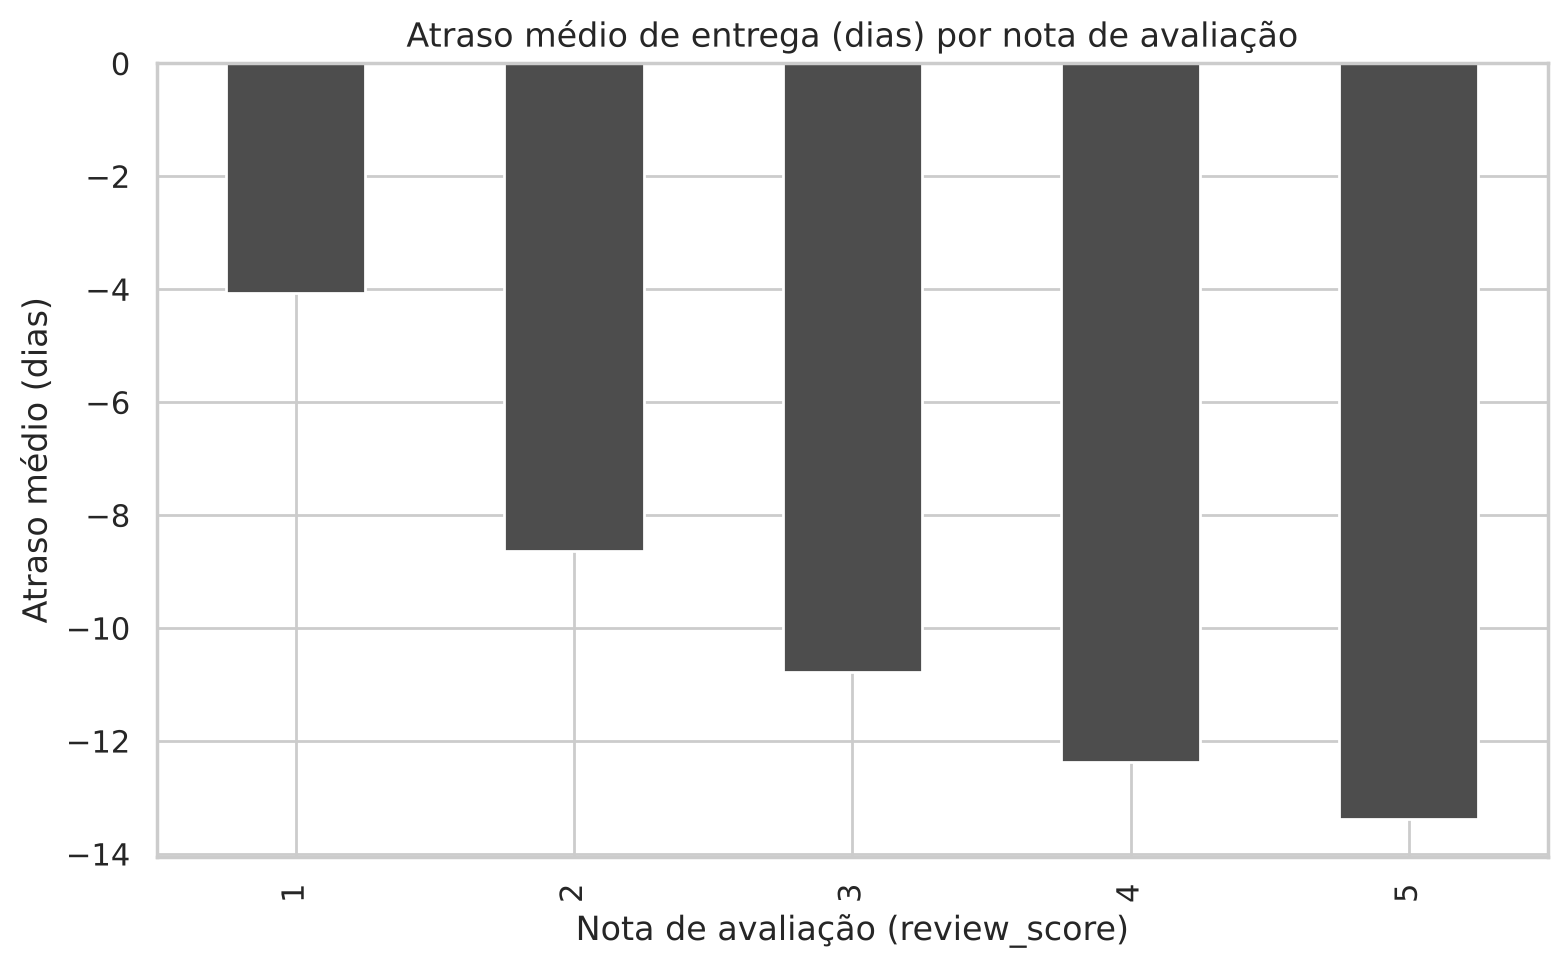

In [20]:
media_atraso_por_nota = orders_reviews.groupby("review_score")["atraso_entrega_dias"].mean()
print("Atraso médio de entrega (dias), por nota de avaliação:")
print(media_atraso_por_nota.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
media_atraso_por_nota.plot(kind="bar", ax=ax, color=COR_PRINCIPAL)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Atraso médio de entrega (dias) por nota de avaliação")
ax.set_xlabel("Nota de avaliação (review_score)")
ax.set_ylabel("Atraso médio (dias)")
plt.tight_layout()
plt.savefig("atraso_medio_por_nota.png", dpi=120)
plt.show()


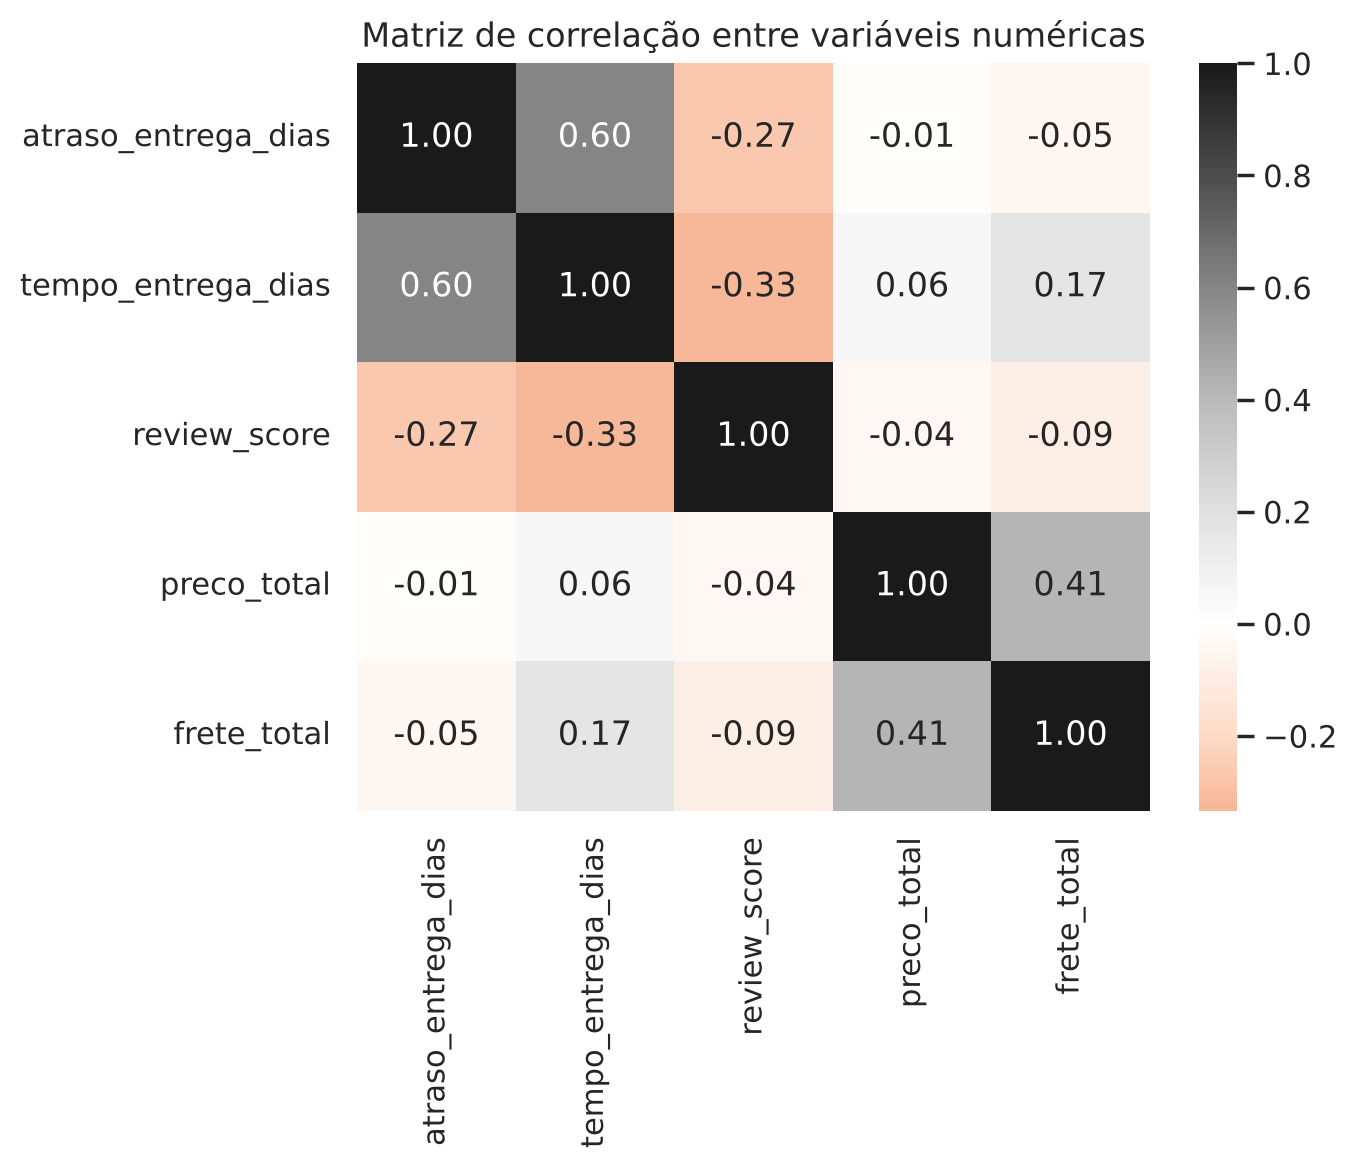

In [21]:
# Matriz de correlação incluindo outras variáveis numéricas de interesse (preço e frete)
itens_pedido = order_items.groupby("order_id").agg(
    preco_total=("price", "sum"),
    frete_total=("freight_value", "sum"),
).reset_index()

base_correlacao = orders_reviews.merge(itens_pedido, on="order_id", how="left")
colunas_num = ["atraso_entrega_dias", "tempo_entrega_dias", "review_score", "preco_total", "frete_total"]
matriz_corr = base_correlacao[colunas_num].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="RdGy", center=0, ax=ax)
ax.set_title("Matriz de correlação entre variáveis numéricas")
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=120)
plt.show()


## 11. Pedidos no prazo × pedidos atrasados

A correlação mostra a *tendência*, mas, para comunicar o resultado (data storytelling), é
mais claro comparar dois grupos: pedidos entregues **até** a data estimada e pedidos
entregues **depois** dela. Para cada grupo calculamos a nota média e a proporção de notas
baixas (1 ou 2), que representam clientes insatisfeitos.

In [22]:
# Consideramos apenas pedidos com data de entrega registrada
entregues = orders_reviews.dropna(subset=["atraso_entrega_dias"]).copy()
entregues["situacao_entrega"] = np.where(entregues["atraso_entrega_dias"] > 0, "Atrasado", "No prazo")
entregues["nota_baixa"] = entregues["review_score"] <= 2

comparacao = entregues.groupby("situacao_entrega").agg(
    pedidos=("order_id", "count"),
    nota_media=("review_score", "mean"),
    pct_notas_baixas=("nota_baixa", "mean"),
)
comparacao["pct_pedidos"] = comparacao["pedidos"] / comparacao["pedidos"].sum() * 100
comparacao["pct_notas_baixas"] = comparacao["pct_notas_baixas"] * 100
comparacao.round(2)

,pedidos,nota_media,pct_notas_baixas,pct_pedidos
situacao_entrega,,,,
Atrasado,6410,2.27,62.40,6.65
No prazo,89949,4.29,9.28,93.35


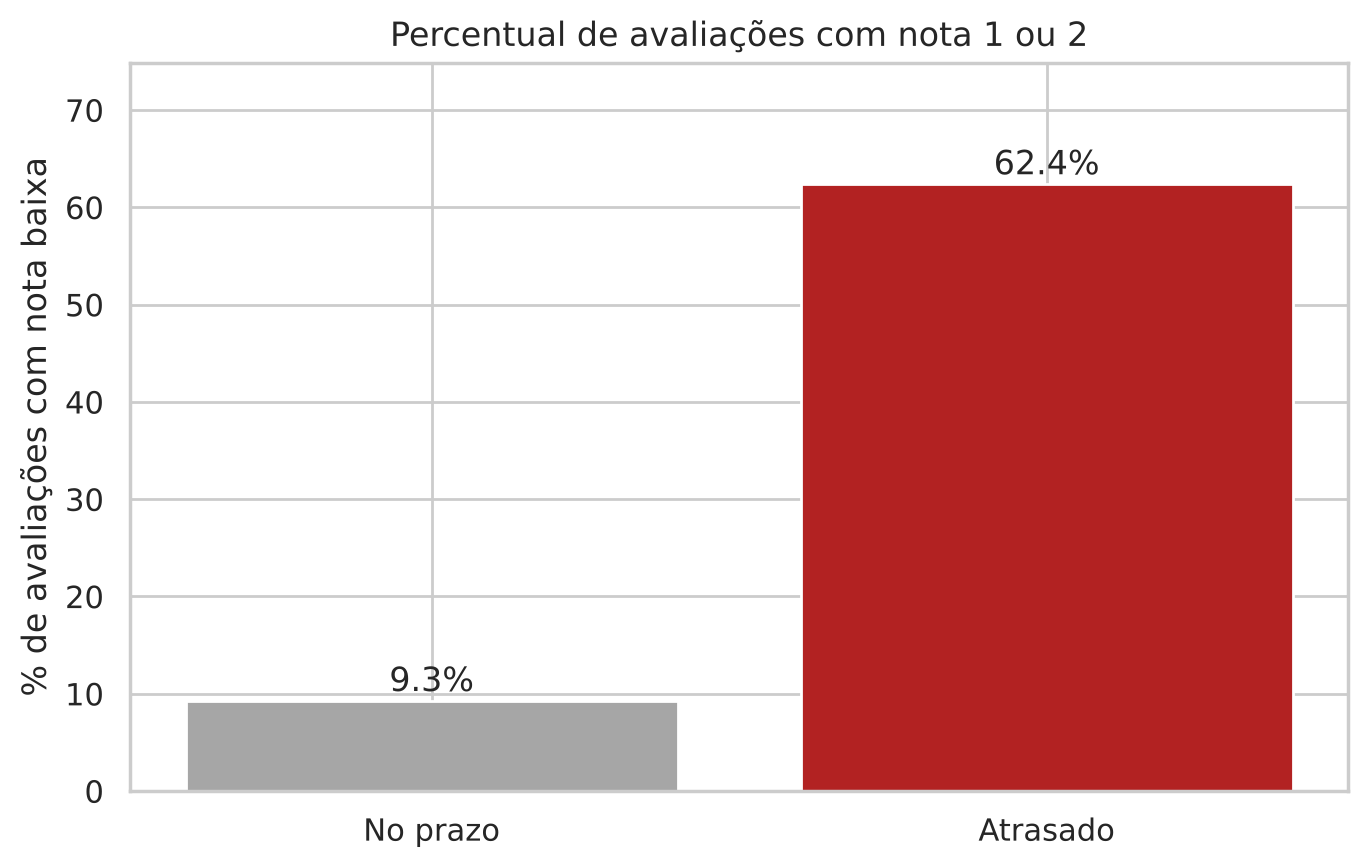

In [23]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ordem = ["No prazo", "Atrasado"]
valores = comparacao.loc[ordem, "pct_notas_baixas"]
barras = ax.bar(ordem, valores, color=[COR_SECUNDARIA, COR_DESTAQUE])
for barra, v in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=12)
ax.set_title("Percentual de avaliações com nota 1 ou 2")
ax.set_ylabel("% de avaliações com nota baixa")
ax.set_ylim(0, valores.max() * 1.2)
plt.tight_layout()
plt.savefig("notas_baixas_prazo_vs_atraso.png", dpi=120)
plt.show()

In [24]:
# Como a nota média muda conforme o tamanho do atraso?
faixas = [-np.inf, 0, 3, 7, 14, np.inf]
rotulos = ["No prazo", "1 a 3 dias", "4 a 7 dias", "8 a 14 dias", "Mais de 14 dias"]
entregues["faixa_atraso"] = pd.cut(entregues["atraso_entrega_dias"], bins=faixas, labels=rotulos)

nota_por_faixa = entregues.groupby("faixa_atraso", observed=True).agg(
    pedidos=("order_id", "count"),
    nota_media=("review_score", "mean"),
    pct_notas_baixas=("nota_baixa", "mean"),
)
nota_por_faixa["pct_notas_baixas"] = nota_por_faixa["pct_notas_baixas"] * 100
nota_por_faixa.round(2)

,pedidos,nota_media,pct_notas_baixas
faixa_atraso,,,
No prazo,89949,4.29,9.28
1 a 3 dias,1856,3.29,32.17
4 a 7 dias,1756,2.10,67.65
8 a 14 dias,1453,1.68,79.97
Mais de 14 dias,1345,1.72,78.29


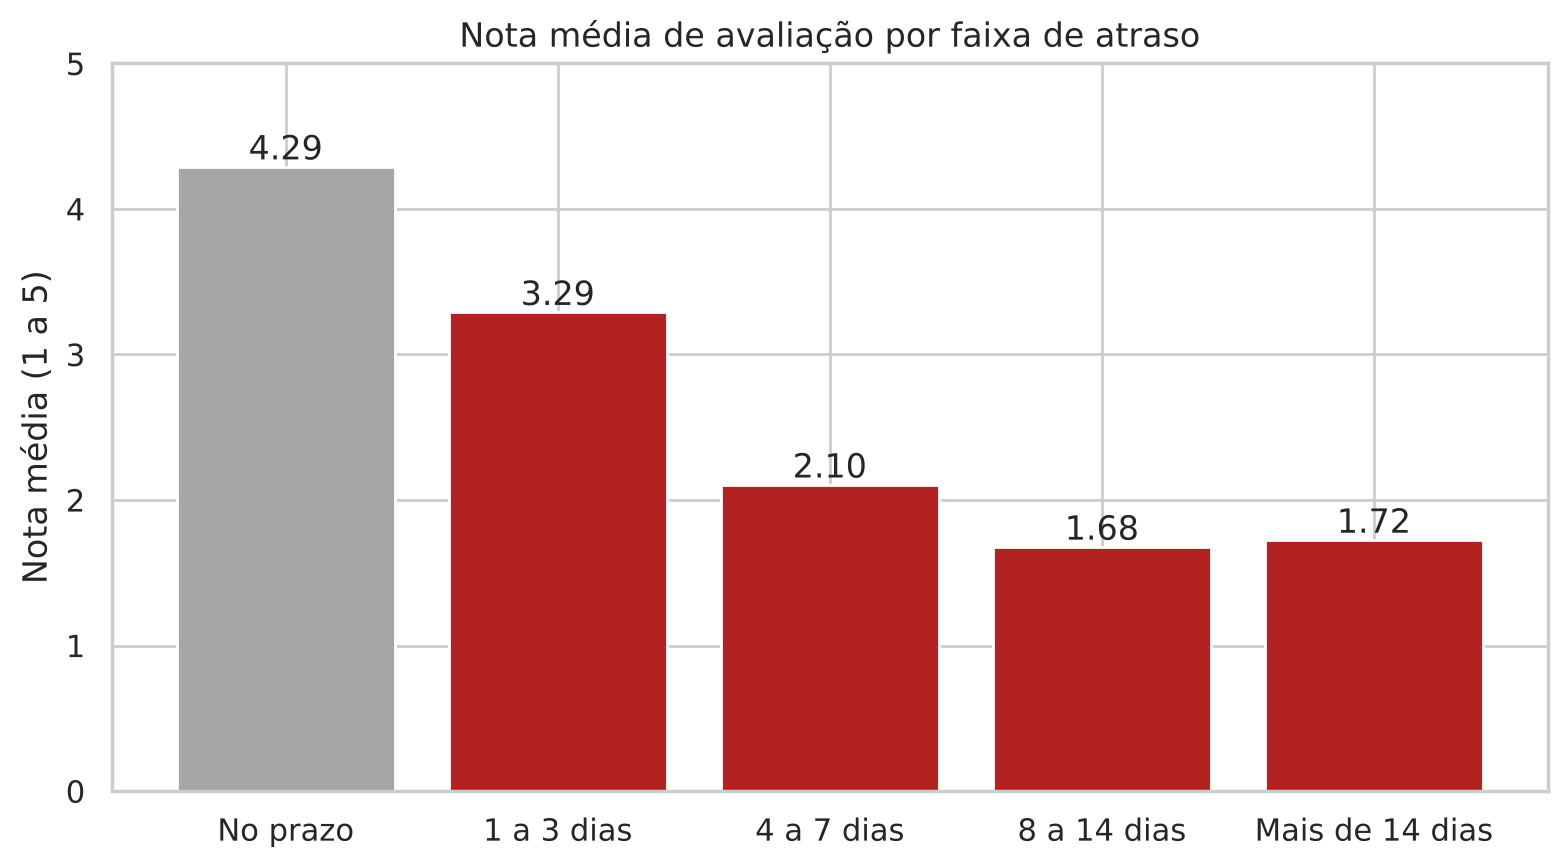

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cores = [COR_SECUNDARIA] + [COR_DESTAQUE] * (len(nota_por_faixa) - 1)
ax.bar(nota_por_faixa.index.astype(str), nota_por_faixa["nota_media"], color=cores)
for i, v in enumerate(nota_por_faixa["nota_media"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_title("Nota média de avaliação por faixa de atraso")
ax.set_ylabel("Nota média (1 a 5)")
ax.set_ylim(0, 5)
plt.tight_layout()
plt.savefig("nota_media_por_faixa_atraso.png", dpi=120)
plt.show()

## 12. Atraso por estado do cliente

A proposta de solução analítica (Seção 10 do documento) sugere acompanhar o desempenho de
entrega por região. Aqui verificamos se a taxa de atraso varia entre os estados do cliente.
Para evitar conclusões baseadas em poucos pedidos, mostramos apenas estados com pelo menos
500 pedidos entregues.

In [26]:
entregues_uf = entregues.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")

por_estado = entregues_uf.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    pct_atrasados=("situacao_entrega", lambda s: (s == "Atrasado").mean() * 100),
    nota_media=("review_score", "mean"),
    tempo_medio_entrega=("tempo_entrega_dias", "mean"),
)
por_estado = por_estado[por_estado["pedidos"] >= 500].sort_values("pct_atrasados", ascending=False)
por_estado.round(2)

,pedidos,pct_atrasados,nota_media,tempo_medio_entrega
customer_state,,,,
MA,716,17.04,3.84,20.94
CE,1276,13.71,3.94,20.76
BA,3246,11.95,3.93,18.80
RJ,12284,11.92,3.96,14.79
PA,939,10.65,3.91,23.19
ES,1978,10.36,4.08,15.16
PB,513,10.14,4.08,19.75
MS,710,9.58,4.17,15.21
PE,1590,9.37,4.09,17.86


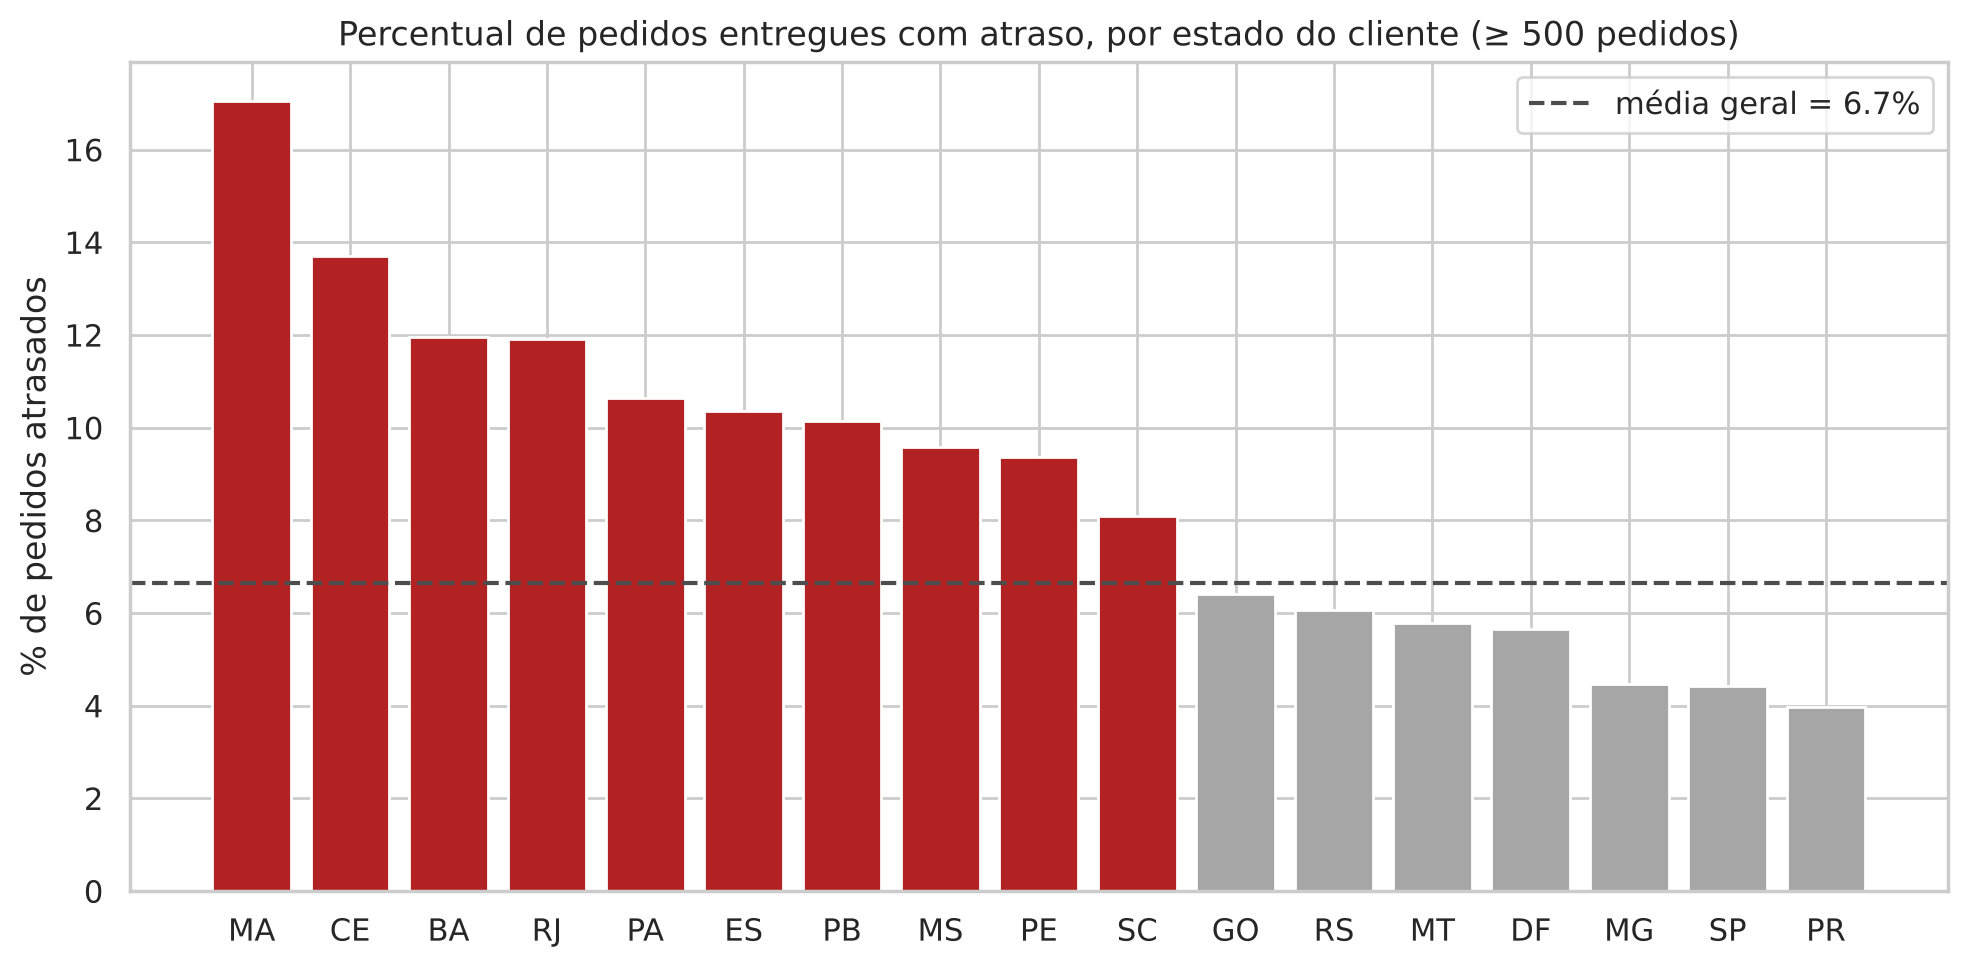

Correlação entre % de atrasados e nota média, entre os estados: -0.909


In [27]:
media_geral = (entregues["situacao_entrega"] == "Atrasado").mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
cores = [COR_DESTAQUE if v > media_geral else COR_SECUNDARIA for v in por_estado["pct_atrasados"]]
ax.bar(por_estado.index, por_estado["pct_atrasados"], color=cores)
ax.axhline(media_geral, color=COR_PRINCIPAL, linestyle="--", label=f"média geral = {media_geral:.1f}%")
ax.set_title("Percentual de pedidos entregues com atraso, por estado do cliente (≥ 500 pedidos)")
ax.set_ylabel("% de pedidos atrasados")
ax.legend()
plt.tight_layout()
plt.savefig("atraso_por_estado.png", dpi=120)
plt.show()

print("Correlação entre % de atrasados e nota média, entre os estados:",
      round(por_estado["pct_atrasados"].corr(por_estado["nota_media"]), 3))

## 13. Síntese dos achados

- O dataset contém **99.441 pedidos**; cerca de **3%** não têm data de entrega ao cliente
  registrada (em sua maioria pedidos não entregues: enviados, cancelados ou indisponíveis).
- O perfil por coluna mostra poucos valores ausentes fora dos comentários de avaliação e
  dos atributos descritivos de produto, e várias variáveis monetárias e de peso com
  distribuição assimétrica à direita (muitos outliers pelo IQR).
- A maior parte dos pedidos chega **antes** da data estimada, mas há uma cauda de atrasos
  longos (até 188 dias).
- A correlação entre atraso e nota é **negativa** e o tempo total de entrega tem correlação
  ainda mais forte com a nota.
- Comparando grupos, a proporção de notas 1–2 entre pedidos **atrasados** é muito maior do
  que entre pedidos entregues no prazo, e a nota média cai a cada faixa de atraso.
- A taxa de atraso **varia entre estados**, o que sustenta a proposta de um painel de
  monitoramento por região.

Os valores exatos estão nas saídas das células acima e são reproduzidos na Seção 11 e no
Esboço do Storytelling do documento da Etapa 3.